# 02 · Training the fraud detector

I wanted to know whether a small ANN could catch more fraud than two tabular baselines at a reasonable review workload. Each row is one payment. The inputs are elapsed seconds (`Time`), transaction amount and 28 anonymized PCA components. `Class` is the label: 1 for fraud and 0 for legitimate. Only 492 of the 284,807 rows are frauds. Calling every payment legitimate would score 99.83% accuracy.

I use the Drive copy at `Dataset/creditcard.csv`, with KaggleHub as a fallback. [ULB dataset card](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
project = Path("/content/drive/MyDrive/Colab Notebooks/Project 01: Intelligent Financial Fraud Detection")
if not project.is_dir():
    raise FileNotFoundError(f"Check your mounted Drive or edit the project path: {project}")
csv_path = project / "Dataset" / "creditcard.csv"
# If the Drive copy is missing, use KaggleHub's runtime cache.
if not csv_path.is_file():
    import kagglehub
    csv_path = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud")) / "creditcard.csv"
print(csv_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/Project 01: Intelligent Financial Fraud Detection/Dataset/creditcard.csv


In [4]:
import copy
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve, auc,
                             confusion_matrix, precision_score, recall_score)
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# These 30 columns will be known at scoring time. Class is the answer used to teach the model.
features = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
df = pd.read_csv(csv_path, usecols=features + ["Class"]).sort_values("Time", kind="stable")
if not np.isfinite(df.to_numpy()).all() or set(df.Class.unique()) != {0, 1}:
    raise ValueError("Expected finite ULB features and binary labels 0 and 1.")
print(f"{len(df):,} transactions | {device} runtime")

284,807 transactions | cuda runtime


## Splitting by transaction time

I train on earlier payments and evaluate on later ones. I keep equal timestamps together and fit the scaler on training rows so future transactions cannot affect the training statistics.

In [5]:
times = df.Time.to_numpy()
# Choose cutoffs by row position, then split by time so equal timestamps stay together.
cut1, cut2 = times[[int(.70 * len(df)), int(.85 * len(df))]]
train = df[df.Time < cut1]
valid = df[(df.Time >= cut1) & (df.Time < cut2)]
test = df[df.Time >= cut2]
for name, part in [("train", train), ("validation", valid), ("test", test)]:
    if part.Class.nunique() != 2:
        raise ValueError(f"{name} needs both classes for evaluation.")
print(train.Class.value_counts().rename("training transactions"))
print(f"Always predicting legitimate yields training accuracy {1 - train.Class.mean():.2%}.")
# Learn the average and spread of each input from past transactions only.
scaler = StandardScaler().fit(train[features])

def arrays(part):
    # Apply those same training statistics to each window. X holds inputs and y holds labels.
    return scaler.transform(part[features]).astype("float32"), part.Class.to_numpy(dtype="int64")

Xtr, ytr = arrays(train)
Xv, yv = arrays(valid)

Class
0    198980
1       384
Name: training transactions, dtype: int64
Always predicting legitimate yields training accuracy 99.81%.


## Training the ANN

I used 64 and 32 hidden units, ReLU and 20% dropout after the first activation. A missed positive contributes more to the training loss because fraud is rare. I use validation average precision (AP) to choose the epoch. In the reference run, epoch 14 reached 0.8606 validation AP.

In [6]:
model = nn.Sequential(nn.Linear(len(features), 64), nn.ReLU(), nn.Dropout(0.2),
                      nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
# For each fraud example, count how many legitimate examples there are in the training set.
ratio = float((ytr == 0).sum() / ytr.sum())
# Scale the positive-label loss by this ratio so rare frauds contribute more to the update.
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(ratio, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
dataset = TensorDataset(torch.from_numpy(Xtr), torch.tensor(ytr, dtype=torch.float32))
loader = DataLoader(dataset, batch_size=512, shuffle=True)

@torch.inference_mode()
def ann_scores(x):
    model.eval()
    chunks = torch.from_numpy(x).split(4096)
    return torch.cat([model(c.to(device)).flatten().sigmoid().cpu() for c in chunks]).numpy()

best_ap = -1.
for epoch in range(1, 16):
    model.train()
    total_loss = 0.
    for inputs, labels in loader:
        # Clear gradients from the previous update. PyTorch adds new gradients to any already stored.
        optimizer.zero_grad()
        # Flatten [batch size, 1] to match the one-dimensional fraud labels.
        logits = model(inputs.to(device)).flatten()
        loss = loss_fn(logits, labels.to(device))
        loss.backward()
        optimizer.step()
        # Weight each batch mean by its row count so a short final batch counts proportionally.
        total_loss += loss.item() * len(labels)
    # Use validation labels to check how well the model ranks frauds across thresholds.
    ap = average_precision_score(yv, ann_scores(Xv))
    print(f"Epoch {epoch:2d} | training loss {total_loss / len(dataset):.4f} | validation AP {ap:.4f}")
    if ap > best_ap:
        best_ap, best_epoch = ap, epoch
        # Keep a separate copy of this epoch's weights while training continues.
        best_weights = copy.deepcopy(model.state_dict())
    # Patience is measured in epochs since the best validation AP.
    if epoch - best_epoch >= 10:
        break
model.load_state_dict(best_weights)
print(f"Restored epoch {best_epoch}")

Epoch  1 | training loss 0.5214 | validation AP 0.8249
Epoch  2 | training loss 0.2960 | validation AP 0.7983
Epoch  3 | training loss 0.2477 | validation AP 0.8477
Epoch  4 | training loss 0.2343 | validation AP 0.7993
Epoch  5 | training loss 0.2118 | validation AP 0.8194
Epoch  6 | training loss 0.2009 | validation AP 0.8501
Epoch  7 | training loss 0.1944 | validation AP 0.7577
Epoch  8 | training loss 0.1577 | validation AP 0.7715
Epoch  9 | training loss 0.1705 | validation AP 0.7702
Epoch 10 | training loss 0.1508 | validation AP 0.8257
Epoch 11 | training loss 0.1375 | validation AP 0.8418
Epoch 12 | training loss 0.1211 | validation AP 0.8230
Epoch 13 | training loss 0.1316 | validation AP 0.8486
Epoch 14 | training loss 0.1087 | validation AP 0.8606
Epoch 15 | training loss 0.1093 | validation AP 0.8494
Restored epoch 14


## Choosing a cutoff for each model

The ANN, logistic regression and boosted trees have different score scales. I chose the cutoff that maximized each model’s validation F1, then kept those cutoffs for the test window.

In [7]:
# Compare the ANN with a linear classifier and a model that combines many small trees.
baselines = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=500),
    "Boosted trees": HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                                     max_iter=100, random_state=SEED),
}
validation = {"ANN": ann_scores(Xv)}
for name, estimator in baselines.items():
    estimator.fit(Xtr, ytr)
    # Column 1 holds the score for the fraud class. Keep one score per validation row.
    validation[name] = estimator.predict_proba(Xv)[:, 1]

def choose_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    # The last precision-recall point has no threshold. Compare F1 only at actual cutoffs.
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[f1.argmax()])

# Freeze one cutoff per model before evaluating any test predictions.
thresholds = {name: choose_threshold(yv, scores) for name, scores in validation.items()}
display(pd.Series(thresholds, name="validation threshold"))

,validation threshold
ANN,0.999877
Logistic regression,0.999993
Boosted trees,0.781576


## What enters the queue?

The slider changes which validation payments a reviewer would see. Lowering it can recover missed frauds, but each additional legitimate payment also costs a review.

In [8]:
review_threshold = 0.50 # @param {type:"slider", min:0, max:1, step:0.01}
def alert_counts(labels, scores, threshold):
    # Lowering the cutoff sends more transactions to the review queue, including possible false alarms.
    flags = scores >= threshold
    # FP is a legitimate transaction flagged for review. FN is a fraud the model missed.
    tn, fp, fn, tp = confusion_matrix(labels, flags, labels=[0, 1]).ravel()
    return {"Alerts": int(flags.sum()), "True alerts": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": precision_score(labels, flags, zero_division=0),
            "Recall": recall_score(labels, flags, zero_division=0)}

display(pd.Series(alert_counts(yv, validation["ANN"], review_threshold)).to_frame("Validation"))
# I join the label after scoring to check which alerts were fraud.
queue = valid[["Time", "Amount", "Class"]].assign(score=validation["ANN"])
display(queue.loc[queue.score >= review_threshold].nlargest(10, "score"))

,Validation
Alerts,373.000000
True alerts,52.000000
False alerts,321.000000
Missed fraud,4.000000
Precision,0.139410
Recall,0.928571


,Time,Amount,Class,score
223572,143434.0,1.00,1,1.0
223618,143456.0,1.00,1,1.0
230076,146179.0,0.77,1,1.0
234574,148028.0,0.00,1,1.0
238222,149582.0,1.10,1,1.0
226814,144808.0,667.55,1,1.0
229712,146022.0,1.18,1,1.0
235616,148468.0,0.76,1,1.0
235634,148476.0,0.76,1,1.0
212644,138942.0,727.91,1,1.0


## Performance on later transactions

I compared both ranking quality and the decisions at the chosen cutoff. The PR-AUC column uses trapezoidal integration. AP summarizes the same precision–recall points with different weighting.

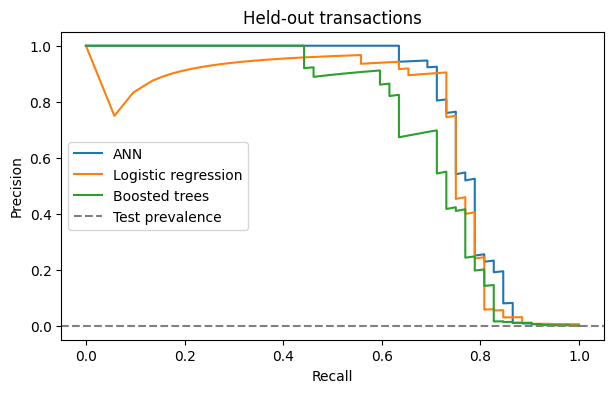

,Threshold,AP,PR-AUC,Alerts,True alerts,False alerts,Missed fraud,Precision,Recall
Model,,,,,,,,,
ANN,0.9999,0.7737,0.7733,39,36,3,16,0.9231,0.6923
Logistic regression,1.0000,0.7069,0.7104,35,33,2,19,0.9429,0.6346
Boosted trees,0.7816,0.7068,0.7058,40,33,7,19,0.8250,0.6346


In [9]:
Xt, yt = arrays(test)
test_scores = {"ANN": ann_scores(Xt)}
for name, estimator in baselines.items():
    test_scores[name] = estimator.predict_proba(Xt)[:, 1]

rows = []
fig, ax = plt.subplots(figsize=(7, 4))
for name, scores in test_scores.items():
    # Trace the tradeoff between correct alerts (precision) and fraud coverage (recall).
    p, r, _ = precision_recall_curve(yt, scores)
    rows.append({"Model": name, "Threshold": thresholds[name], "AP": average_precision_score(yt, scores),
                 "PR-AUC": auc(r, p), **alert_counts(yt, scores, thresholds[name])})
    ax.plot(r, p, label=name)
# The fraud fraction gives a reference precision for random ranking.
ax.axhline(yt.mean(), ls="--", color="gray", label="Test prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Held-out transactions")
ax.legend()
plt.show()
display(pd.DataFrame(rows).set_index("Model").round(4))

## Saving this run

The checkpoint includes the training means, scales and column order. I need all three to score another file with the same weights. The timestamp pairs the weights with the right metrics CSV.

In [10]:
from datetime import datetime, timezone

output = project / "Artifacts"
output.mkdir(exist_ok=True)
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
path = output / f"ann_{stamp}.pt"
# Future scoring needs the same column order and scaling, as well as the trained weights.
torch.save({"state_dict": {k: v.cpu() for k, v in best_weights.items()},
            "features": features, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
            "threshold": thresholds["ANN"], "best_epoch": best_epoch,
            "architecture": "Linear(30,64) ReLU Dropout(0.2) Linear(64,32) ReLU Linear(32,1)"},
           path)
pd.DataFrame(rows).to_csv(output / f"metrics_{stamp}.csv", index=False)
print(path)

/content/drive/MyDrive/Colab Notebooks/Project 01: Intelligent Financial Fraud Detection/Artifacts/ann_20261121T162317186996Z.pt


## What I took from the comparison

The ANN caught 36 of 52 frauds in 39 reviews. Logistic regression caught 33 in 35 reviews. I picked the ANN for the next stage because four extra investigations found three additional frauds. Logistic regression still had the highest precision.